In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/SeoulBikeData.csv", encoding="latin-1")
print(df.columns.tolist())

['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day']


In [3]:
df.columns = ["date", "rented_bike_count", "hour", "temperature", "humidity",
              "wind_speed", "visibility", "dew_point", "solar_radiation",
              "rainfall", "snowfall", "seasons", "holiday", "functioning_day"]
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y")

print(df.shape)
df.head()

(8760, 14)


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point,solar_radiation,rainfall,snowfall,seasons,holiday,functioning_day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


## Exploration Plots

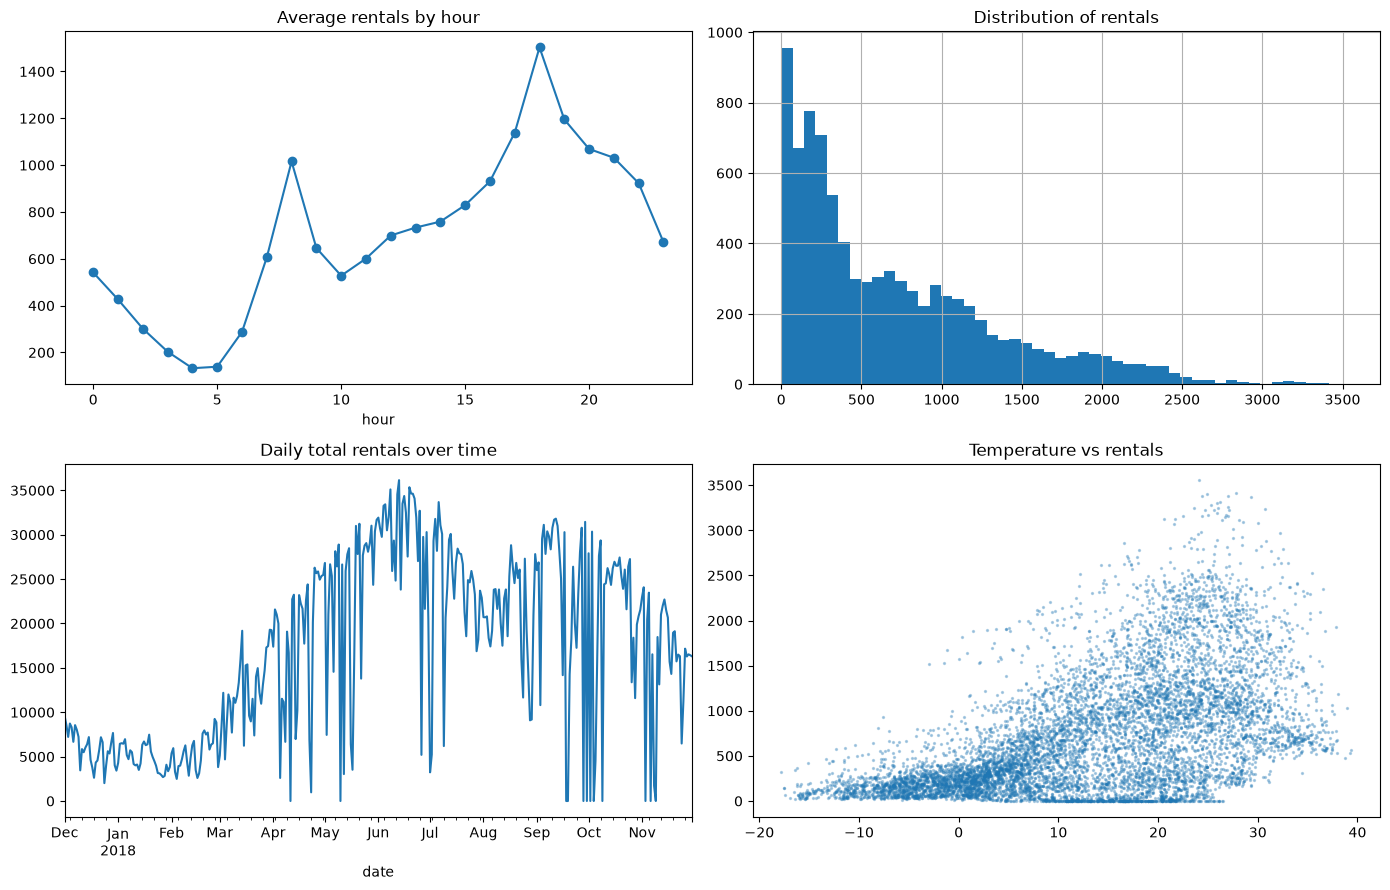

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

df.groupby("hour")["rented_bike_count"].mean().plot(ax=axes[0, 0], marker="o")
axes[0, 0].set_title("Average rentals by hour")

df["rented_bike_count"].hist(bins=50, ax=axes[0, 1])
axes[0, 1].set_title("Distribution of rentals")

df.groupby("date")["rented_bike_count"].sum().plot(ax=axes[1, 0])
axes[1, 0].set_title("Daily total rentals over time")

axes[1, 1].scatter(df["temperature"], df["rented_bike_count"], s=2, alpha=0.3)
axes[1, 1].set_title("Temperature vs rentals")

plt.tight_layout()
plt.show()

In [6]:
print(df.groupby("functioning_day")["rented_bike_count"].describe())
print("\nCorrelation temperature vs dew point:", df["temperature"].corr(df["dew_point"]))
print("\nMissing values:\n", df.isna().sum())

                  count        mean         std  min    25%    50%     75%  \
functioning_day                                                              
No                295.0    0.000000    0.000000  0.0    0.0    0.0     0.0   
Yes              8465.0  729.156999  642.351166  2.0  214.0  542.0  1084.0   

                    max  
functioning_day          
No                  0.0  
Yes              3556.0  

Correlation temperature vs dew point: 0.9127982187579923

Missing values:
 date                 0
rented_bike_count    0
hour                 0
temperature          0
humidity             0
wind_speed           0
visibility           0
dew_point            0
solar_radiation      0
rainfall             0
snowfall             0
seasons              0
holiday              0
functioning_day      0
dtype: int64


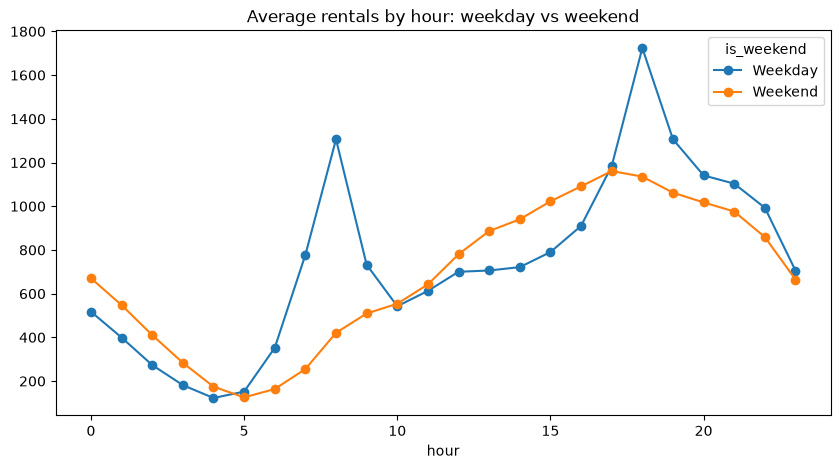

date
2018-04-11    24
2018-05-10    24
2018-09-18    24
2018-09-19    24
2018-09-28    24
2018-09-30    24
2018-10-02    24
2018-10-04    24
2018-10-06     7
2018-10-09    24
2018-11-03    24
2018-11-06    24
2018-11-09    24
dtype: int64

Dew point explained by temperature + humidity: R² = 0.990


In [10]:
from sklearn.linear_model import LinearRegression

df["weekday"] = df["date"].dt.dayofweek
df["is_weekend"] = df["weekday"] >= 5
open_hours = df[df["functioning_day"] == "Yes"]

(open_hours.groupby(["hour", "is_weekend"])["rented_bike_count"]
    .mean().unstack()
    .rename(columns={False: "Weekday", True: "Weekend"})
    .plot(marker="o", figsize=(10, 5), title="Average rentals by hour: weekday vs weekend"))
plt.show()

print(df[df["functioning_day"] == "No"].groupby("date").size())

X = df[["temperature", "humidity"]]
r2 = LinearRegression().fit(X, df["dew_point"]).score(X, df["dew_point"])
print(f"\nDew point explained by temperature + humidity: R² = {r2:.3f}")